# Lidar a fotogrammetrie v lese: mračna bodů a modely ČÚZK

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/lidar_canopy_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [LiDAR a fotogrammetrie v porostu](https://openskylab.space/edu_viz_lidar_canopy.html) · [English version](lidar_canopy_en.ipynb)

Vizuál ukazuje, proč laserový pulz najde terén i pod korunami, zatímco fotogrammetrie vidí jen povrch. Tady to ověříš na skutečných datech ČÚZK z Roztockého háje u Suchdola: body terénu a povrchu z leteckého laserového skenování a povrch z obrazové korelace leteckých snímků.

**Cíl:** načíst a prohlédnout mračna bodů LAZ, zjistit, z kolikátého odrazu pocházejí body terénu v lese a na volné ploše, spočítat model výšky porostu CHM = DSM − DTM z lidaru i z fotogrammetrie, porovnat je v profilu, najít vrcholy stromů a vysvětlit rozdíly.

**Data:** ČÚZK: DMR 5G (body terénu z leteckého laserového skenování, LAZ) a DMP 1G (body povrchu, LAZ) pro mapový list Kralupy nad Vltavou 7-7, rastry DMR 5G, DMP 1G a DMP OK (obrazová korelace) z obrazové služby ČÚZK; vše v S-JTSK (EPSG:5514), výšky Bpv. Data ČÚZK jsou otevřená (CC BY 4.0).

**Úkoly:** šest. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 50 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a mračna bodů

In [1]:
%pip install -q "laspy[lazrs]" rasterio

Note: you may need to restart the kernel to use updated packages.


výřez 1.0 × 0.7 km, skenováno kolem 09. 10. 2010
                           bodů  bodů na m²
DMR 5G: terén             62555       0.089
DMP 1G: terén             12834       0.018
DMP 1G: vysoká vegetace  139724       0.200
DMP 1G: budovy            12713       0.018


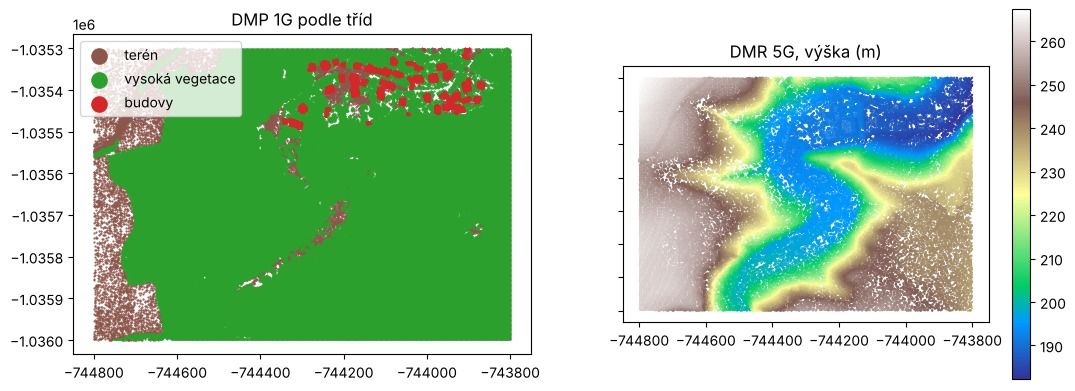

In [2]:
import io, time, zipfile, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import laspy, rasterio
from scipy import ndimage as ndi

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

SHEET = "KRAV77"              # ◀ parametr: mapový list SM5 (názvy listů jsou v atomové službě ČÚZK)
X0, Y0, X1, Y1 = -744800, -1036000, -743800, -1035300   # ◀ parametr: výřez v S-JTSK (m), Roztocký háj a Tiché údolí

def laz(product, sheet, tries=4):
    for i in range(tries):
        try:
            r = requests.get(f"https://openzu.cuzk.gov.cz/opendata/{product}/epsg-5514/{sheet}.zip", timeout=180); r.raise_for_status(); break
        except requests.RequestException as e:
            print(product, type(e).__name__, "– zkusím znovu"); time.sleep(5 * (i + 1))
    z = zipfile.ZipFile(io.BytesIO(r.content))
    las = laspy.read(io.BytesIO(z.read(z.namelist()[0])))
    m = (las.x >= X0) & (las.x < X1) & (las.y >= Y0) & (las.y < Y1)
    return las.points[m]

ground = laz("DMR5G", SHEET)          # body terénu (klíčové body modelu reliéfu)
surface = laz("DMP1G", SHEET)         # body povrchu: 2 terén, 5 vysoká vegetace, 6 budovy
area = (X1 - X0) * (Y1 - Y0)
gps = np.median(np.asarray(ground.gps_time)) + 1e9          # „adjusted GPS time“ = sekundy od 6. 1. 1980 minus 10⁹
print(f"výřez {(X1 - X0) / 1000:.1f} × {(Y1 - Y0) / 1000:.1f} km, skenováno kolem {pd.Timestamp('1980-01-06') + pd.Timedelta(seconds=gps):%d. %m. %Y}")
CLS = {2: "terén", 5: "vysoká vegetace", 6: "budovy"}
tab = pd.DataFrame({"bodů": [len(ground)] + [int((surface.classification == c).sum()) for c in CLS]},
                   index=["DMR 5G: terén"] + [f"DMP 1G: {n}" for n in CLS.values()])
tab["bodů na m²"] = tab["bodů"] / area
print(tab.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for c, col in zip(CLS, ["tab:brown", "tab:green", "tab:red"]):
    s = surface.classification == c
    ax[0].scatter(surface.x[s], surface.y[s], s=0.3, c=col, label=CLS[c])
ax[0].legend(markerscale=20); ax[0].set_title("DMP 1G podle tříd"); ax[0].set_aspect("equal")
sc = ax[1].scatter(ground.x, ground.y, s=0.3, c=ground.z, cmap="terrain"); ax[1].set_title("DMR 5G, výška (m)"); ax[1].set_aspect("equal")
plt.colorbar(sc, ax=ax[1]); plt.show()

> **✏️ Úkol 1.** Kolik bodů na m² mají DMR 5G a DMP 1G? Skener jich na zem poslal mnohem víc: proč ČÚZK zveřejňuje jen vybrané (klíčové) body a podle čeho je asi vybíral? Ve kterém měsíci se skenovalo? Jak ovlivní listí, kolik pulzů projde až na zem, a proč se lidar pro model terénu ideálně létá mimo vegetační sezónu?

*Tvoje odpověď:* 

## 2. Z kolikátého odrazu je terén?

Každý bod nese číslo odrazu (return number) a počet odrazů pulzu (number of returns). Bod terénu s číslem odrazu 2 a víc znamená, že část pulzu se předtím odrazila od koruny a zbytek prošel mezerou až na zem. Les od volné plochy rozlišíme podle výšky povrchu nad terénem z rastrů DMP 1G a DMR 5G.

bodů terénu: v lese 49675 (0.089/m²), na volné ploše 12880 (0.091/m²)
               les  volná plocha
číslo odrazu                    
1             16.2          78.7
2             47.6          17.7
3             29.7           3.4
4              6.1           0.2
5              0.5           0.0
6              0.0           0.0


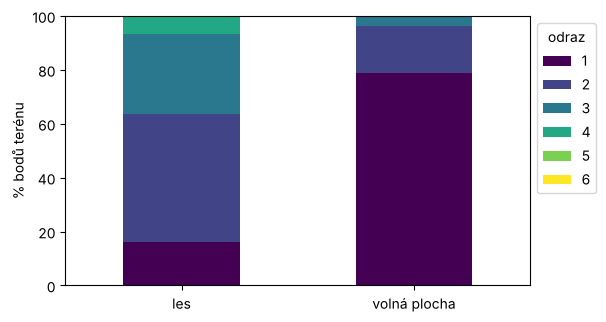

In [3]:
RES = 2.0                     # ◀ parametr: velikost pixelu rastrů (m)
FOREST_H = 5                  # ◀ parametr: od jaké výšky povrchu nad terénem je to „les“ (m)
dtm, tf = cuzk_raster("dmr5g", X0, Y0, X1, Y1, RES)
dsm_l, _ = cuzk_raster("dmp1g", X0, Y0, X1, Y1, RES)
chm_l = dsm_l - dtm
r, c = rasterio.transform.rowcol(tf, np.asarray(ground.x), np.asarray(ground.y))
forest = chm_l[np.clip(r, 0, chm_l.shape[0] - 1), np.clip(c, 0, chm_l.shape[1] - 1)] > FOREST_H
rn = np.asarray(ground.return_number)
share = pd.DataFrame({"les": pd.Series(rn[forest]).value_counts(normalize=True), "volná plocha": pd.Series(rn[~forest]).value_counts(normalize=True)}).fillna(0) * 100
share.index.name = "číslo odrazu"
print(f"bodů terénu: v lese {forest.sum()} ({forest.sum() / ((chm_l > FOREST_H).sum() * RES**2):.3f}/m²), na volné ploše {(~forest).sum()} ({(~forest).sum() / ((chm_l <= FOREST_H).sum() * RES**2):.3f}/m²)")
print(share.round(1))
share.T.plot.bar(stacked=True, figsize=(6, 3.5), colormap="viridis", ylabel="% bodů terénu", rot=0); plt.legend(title="odraz", bbox_to_anchor=(1, 1)); plt.show()

> **✏️ Úkol 2.** Jaký podíl bodů terénu v lese pochází z 2. a dalšího odrazu a jaký na volné ploše? Proč není na volné ploše nula? Co by se stalo s modelem terénu pod lesem, kdyby skener zaznamenával jen první odraz? A proč fotogrammetrie (SfM) terén pod zapojeným porostem nenajde vůbec?

*Tvoje odpověď:* 

## 3. CHM z lidaru a z fotogrammetrie

CHM = DSM − DTM. DTM bereme vždy z lidaru (DMR 5G). DSM jednou z lidaru (DMP 1G), jednou z obrazové korelace leteckých měřických snímků (DMP OK), které ČÚZK pořídil později (letecké měřické snímkování probíhá obvykle od jara do léta). Obrazová korelace je stejný princip jako fotogrammetrie z dronu.

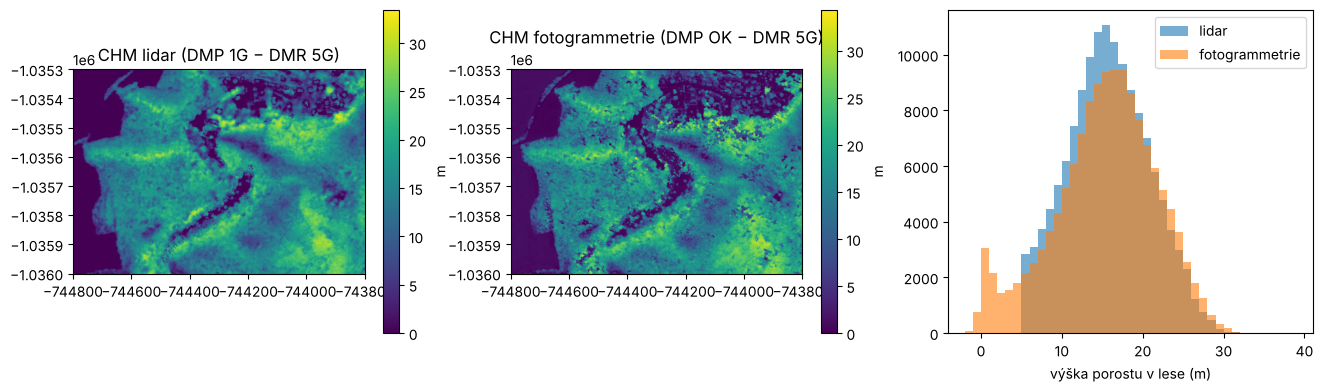

      lidar  fotogrammetrie
mean   15.8            15.3
50%    15.8            15.8
95%    24.4            25.0
max    33.4            34.4


In [4]:
dsm_p, _ = cuzk_raster("dmp_obrazova_korelace", X0, Y0, X1, Y1, RES)
chm_p = dsm_p - dtm
ext = (X0, X1, Y0, Y1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (name, v) in zip(ax, [("CHM lidar (DMP 1G − DMR 5G)", chm_l), ("CHM fotogrammetrie (DMP OK − DMR 5G)", chm_p)]):
    im = a.imshow(np.clip(v, 0, 35), extent=ext, cmap="viridis"); a.set_title(name); plt.colorbar(im, ax=a, label="m")
bins = np.arange(-2, 40, 1)
ax[2].hist(chm_l[chm_l > FOREST_H], bins, alpha=0.6, label="lidar"); ax[2].hist(chm_p[chm_l > FOREST_H], bins, alpha=0.6, label="fotogrammetrie")
ax[2].set_xlabel("výška porostu v lese (m)"); ax[2].legend(); plt.show()
fm = chm_l > FOREST_H
print(pd.DataFrame({"lidar": pd.Series(chm_l[fm]).describe(percentiles=[0.5, 0.95]), "fotogrammetrie": pd.Series(chm_p[fm]).describe(percentiles=[0.5, 0.95])}).loc[["mean", "50%", "95%", "max"]].round(1))

> **✏️ Úkol 3.** Který CHM ukazuje v lese vyšší porost a o kolik (medián, 95. percentil)? Najdi aspoň tři důvody: roky mezi snímkováním, listí v létě a v době skenování, jak obrazová korelace „vyhlazuje“ mezery mezi korunami. Kde v mapě jsou rozdíly největší?

*Tvoje odpověď:* 

## 4. Profil porostem

Body obou mračen v pásu podél zvolené čáry a profily tří povrchů.

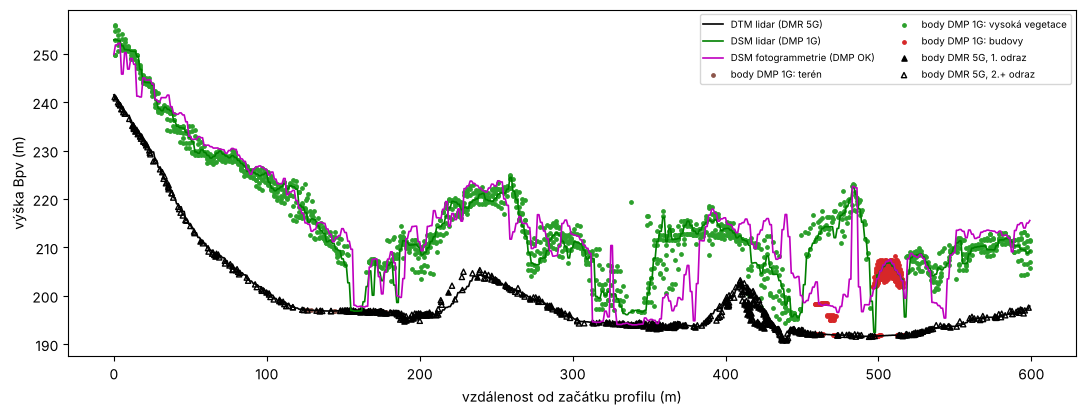

In [5]:
A_XY = (-744300, -1035950)    # ◀ parametr: začátek profilu (S-JTSK, m)
B_XY = (-744300, -1035350)    # ◀ parametr: konec profilu
HALF_W = 5                    # ◀ parametr: poloviční šířka pásu (m)
a, b = np.array(A_XY, float), np.array(B_XY, float); u = (b - a) / np.linalg.norm(b - a); n = np.array([-u[1], u[0]])
def strip(pts):
    d = np.c_[np.asarray(pts.x), np.asarray(pts.y)] - a
    s, o = d @ u, d @ n; m = (np.abs(o) <= HALF_W) & (s >= 0) & (s <= np.linalg.norm(b - a))
    return s[m], np.asarray(pts.z)[m], m
s_vals = np.arange(0, np.linalg.norm(b - a), RES / 2)
xy = a + np.outer(s_vals, u)
rr, cc = rasterio.transform.rowcol(tf, xy[:, 0], xy[:, 1])
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, v, st in [("DTM lidar (DMR 5G)", dtm, "k-"), ("DSM lidar (DMP 1G)", dsm_l, "g-"), ("DSM fotogrammetrie (DMP OK)", dsm_p, "m-")]:
    ax.plot(s_vals, v[rr, cc], st, lw=1.2, label=name)
s, z, m = strip(surface)
for cl, col in zip(CLS, ["tab:brown", "tab:green", "tab:red"]):
    k = np.asarray(surface.classification)[m] == cl; ax.scatter(s[k], z[k], s=6, c=col, label=f"body DMP 1G: {CLS[cl]}")
s, z, m = strip(ground); k = np.asarray(ground.return_number)[m] > 1
ax.scatter(s[~k], z[~k], s=14, marker="^", c="k", label="body DMR 5G, 1. odraz"); ax.scatter(s[k], z[k], s=14, marker="^", facecolors="none", edgecolors="k", label="body DMR 5G, 2.+ odraz")
ax.set_xlabel("vzdálenost od začátku profilu (m)"); ax.set_ylabel("výška Bpv (m)"); ax.legend(fontsize=7, ncol=2); plt.show()

> **✏️ Úkol 4.** Kde v profilu je les a kde volná plocha? Jak se liší DSM z lidaru a z fotogrammetrie na okraji lesa a v mezerách mezi korunami? Které body terénu jsou v lese z 2. a dalšího odrazu? Přesuň profil jinam (třeba přes údolí nebo budovy) a popiš, co vidíš.

*Tvoje odpověď:* 

## 5. Vrcholy stromů

Vrchol stromu hledáme jako lokální maximum CHM v okně dané velikosti, které je vyšší než zvolená mez. Použijeme fotogrammetrický DSM v plném rozlišení 0,5 m.

okno 5 m, mez 10 m: 785 vrcholů na 9.0 ha = 87 stromů/ha, medián výšky 19.6 m


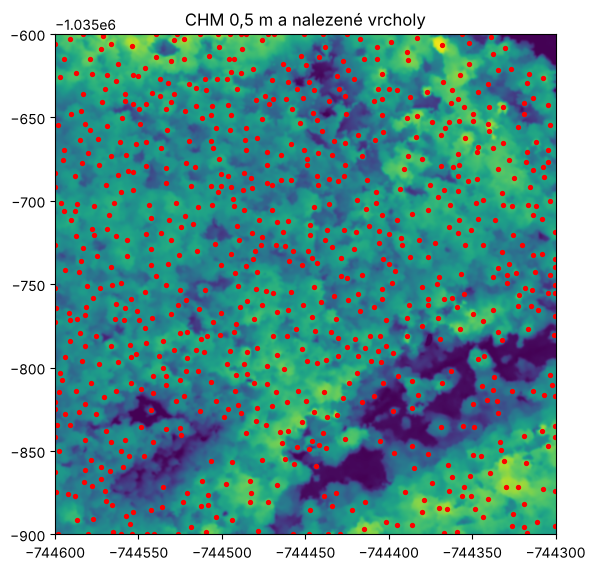

In [6]:
WIN = 5                       # ◀ parametr: velikost okna pro lokální maximum (m)
MIN_H = 10                    # ◀ parametr: minimální výška stromu (m)
SUB = (-744600, -1035900, -744300, -1035600)   # ◀ parametr: menší výřez v lese (S-JTSK, m)
d05, t05 = cuzk_raster("dmp_obrazova_korelace", *SUB, res=0.5)
g05, _ = cuzk_raster("dmr5g", *SUB, res=0.5)
chm05 = ndi.gaussian_filter(d05 - g05, 1)
k = max(3, int(round(WIN / 0.5)) | 1)
tops = (chm05 == ndi.maximum_filter(chm05, size=k)) & (chm05 > MIN_H)
rows_, cols_ = np.nonzero(tops)
ha = (SUB[2] - SUB[0]) * (SUB[3] - SUB[1]) / 1e4
print(f"okno {WIN} m, mez {MIN_H} m: {tops.sum()} vrcholů na {ha:.1f} ha = {tops.sum() / ha:.0f} stromů/ha, medián výšky {np.median(chm05[tops]):.1f} m")
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(np.clip(chm05, 0, 35), cmap="viridis", extent=(SUB[0], SUB[2], SUB[1], SUB[3]))
xs, ys = rasterio.transform.xy(t05, rows_, cols_)
ax.scatter(xs, ys, s=8, c="r"); ax.set_title("CHM 0,5 m a nalezené vrcholy"); plt.show()

> **✏️ Úkol 5.** Kolik stromů na hektar najdeš s oknem 3 m, 5 m a 9 m? Které číslo je nejblíž skutečnosti, pokud mají koruny průměr kolem 8–12 m, a proč malé okno počet přeceňuje? Co by se stalo s počtem, kdybys použil CHM z lidaru s pixelem 2 m?

*Tvoje odpověď:* 

## 6. Co se mezi snímkováními změnilo

Rozdíl CHM z fotogrammetrie a z lidaru ukazuje růst porostu, těžbu i chyby obou metod. Přesnost udává ČÚZK jako úplnou střední chybu výšky: DMR 5G 0,18 m v odkrytém a 0,3 m v zalesněném terénu, DMP 1G 0,4 m u budov a 0,7 m u vegetace.

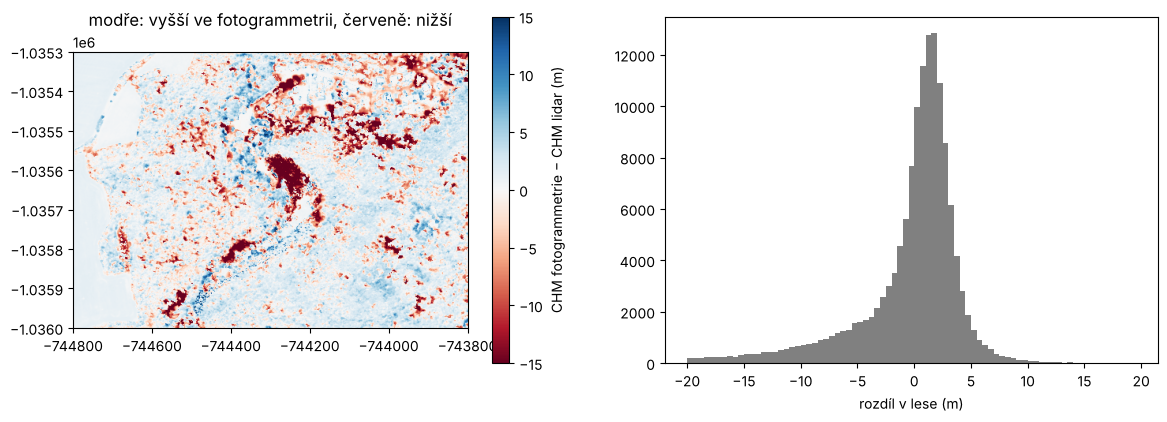

v lese: medián rozdílu +0.8 m; o víc než 5 m výš 4 %, o víc než 5 m níž 13 % plochy


In [7]:
CHANGE = 5                    # ◀ parametr: od jakého rozdílu výšky (m) to považujeme za změnu
diff = chm_p - chm_l
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
im = ax[0].imshow(np.clip(diff, -15, 15), extent=ext, cmap="RdBu"); plt.colorbar(im, ax=ax[0], label="CHM fotogrammetrie − CHM lidar (m)")
ax[0].set_title("modře: vyšší ve fotogrammetrii, červeně: nižší")
ax[1].hist(diff[fm], np.arange(-20, 20, 0.5), color="gray"); ax[1].set_xlabel("rozdíl v lese (m)"); plt.show()
print(f"v lese: medián rozdílu {np.median(diff[fm]):+.1f} m; o víc než {CHANGE} m výš {100 * (diff[fm] > CHANGE).mean():.0f} %, o víc než {CHANGE} m níž {100 * (diff[fm] < -CHANGE).mean():.0f} % plochy")

> **✏️ Úkol 6.** Je medián rozdílu v lese větší, než vysvětlí udávaná přesnost obou modelů? Kolik by musel les za ta léta vyrůst a je to realistické (dohledej, jaký je typický roční výškový přírůst dospělého listnatého lesa)? Najdi v mapě místa, kde porost zmizel (těžba, polom) nebo přibyl. Proč nejde z jednoho fotogrammetrického DSM bez lidarového DTM výšku porostu vůbec spočítat?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- ČÚZK: Digitální model reliéfu České republiky 5. generace (DMR 5G), úplná střední chyba výšky 0,18 m v odkrytém a 0,3 m v zalesněném terénu; Digitální model povrchu České republiky 1. generace (DMP 1G), úplná střední chyba výšky 0,4 m u budov a 0,7 m u vegetace; Digitální model povrchu z obrazové korelace (DMP OK). https://geoportal.cuzk.gov.cz
- Stahování LAZ: atomová služba ČÚZK, https://atom.cuzk.cz/DMR5G-SJTSK/DMR5G-SJTSK.xml a https://atom.cuzk.cz/DMP1G-SJTSK/DMP1G-SJTSK.xml; rastry: https://ags.cuzk.cz/arcgis2/rest/services
- ASPRS (2019). *LAS Specification 1.4 – R15* (třídy bodů, čísla odrazů, čas GPS).
- White, J. C., Wulder, M. A., Vastaranta, M. a kol. (2013). The utility of image-based point clouds for forest inventory: A comparison with airborne laser scanning. *Forests* 4(3), 518–536.

### Jak citovat

OpenSkyLab (2026). Lidar a fotogrammetrie v lese: mračna bodů a modely ČÚZK [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/lidar_canopy_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*